# assignment 1, additional report: improved motor model

###### *extends `robotics_lab5_240057.ipynb`*

model is built up in 3 stages (initial model, then an intercept, then speed-dependent loss); the motors are called M3 and M4

initial model: 
 $T_m\dot\omega+\omega=U/k_e$, which assumes the steady speed is proportional to voltage and that $T_m$ is constant, but on my data neither holds: the speed line has an intercept of about +3.6 rad/s (motor M4) and +5.2 rad/s (motor M3) at zero PWM, and $T_m$ falls about six-fold between 10% and 100% PWM. 
 
**step 2**: adding one number per direction (the intercept). It gives a clearly better speed prediction on the held-out sawtooth (in both recording sessions - initial and 2nd ran for this report), an equal one on the square wave, and on the held-out triangle an angle fit of 86-87% against 78-80% for the initial model (the rubric target is 85%). 

**step 3**: let friction depend on speed, which explains the changing $T_m$ and fits the steps much better; on the triangle it is slightly better again, but elsewhere it is not consistently better than stage 2. No step fixes the angle drift of the sawtooth.

## 1. model, step by step

notation: $p$ = PWM in %, $U=pU_b/100$ the applied voltage, $\omega$ wheel speed (rad/s), $\theta$ angle (rad)

every parameter is fitted **separately for forward ($p>0$) and backward ($p<0$)**.

### stage 1: initial model

$$T_m\,\dot\omega+\omega=\omega_{ss},\qquad \omega_{ss}=\frac{U}{k_e}\qquad\Rightarrow\qquad \theta(t)=\omega_{ss}\left(t-T_m+T_me^{-t/T_m}\right)$$

two numbers per direction: $k_e$ and $T_m$. 

steady speed is a straight line **through the origin**.

### stage 2 - add an intercept to the steady speed

$$T_m\,\dot\omega+\omega=\omega_{ss}(p),\qquad \omega_{ss}(p)=\operatorname{sgn}(p)\,\bigl(s\,|p|+b\bigr)\ \ (|p|\ge10\,\%)$$

below 10% the target is ramped linearly to zero, $\omega_{ss}\to\omega_{ss}\cdot|p|/10$ (given that no data below 10% PMW)

step response has the same form as stage 1 with the new $\omega_{ss}$. 

3 numbers per direction: 
- slope $s$ (rad/s per %)
- intercept $b$ (rad/s)
- $T_m$.

course constant is recovered as $k_e=U_b/(100\,s)$

*positive $b$* means the motor already spins at low PWM; => Coulomb friction alone would give a negative $b$, so $b$ is not a friction effect, so I interpret it as an input-stage effect (driver offset), but i cant prove that with current data (i probably should record data with lower starting PWM)

### stage 3 - let loss/friction depend on speed

$$\dot\omega=\operatorname{sgn}(p)\,a(|p|)-\operatorname{sgn}(\omega)\,\phi(|\omega|),\qquad \phi(u)=k_1u+k_2u^2+k_3u^3$$

- $a(|p|)$ is the drive acceleration (rad/s$^2$), table at the tested levels 10, 20, ..., 100%
- $\phi$ is the loss
- => $a(p)=\phi(\omega_{ss})$ and $T_m(\omega)=1/\phi'(\omega)=1/(k_1+2k_2\omega+3k_3\omega^2)$, so $T_m$ falls with speed when $\phi$ is increasing.

if $\phi$ is linear, $\phi=\omega/T_m$ and stage 3 reduces to stage 1

### where formulas come from (derived vs fitted)

**stage 1 is derived from physics ($K_t=K_e=K$ in SI units)** By neglecting inductance ($L$=0), the electrical side is $v=iR+K\omega$ and the torque is $\tau=Ki$. mechanical side is $J\dot\omega=\tau-B\omega$ with viscous drag $B$, and substituting $i$:

$$\dot\omega=\frac{K}{JR}\,v-\frac{K^2/R+B}{J}\,\omega\quad\Rightarrow\quad \frac1{T_m}=\frac{K^2+RB}{JR},\qquad \omega_{ss}=\frac{v}{k_e},\ \ k_e=\frac{K^2+RB}{K}=K+\frac{RB}{K}$$

so $k_e$ measured from the slope is an *apparent* constant: it includes the viscous drag and is slightly larger than the back-EMF constant $K$. solving the 1st order equation with the integrating factor $e^{t/T_m}$ gives $\omega(t)=\omega_{ss}(1-e^{-t/T_m})$, and one integration gives $\theta(t)$ (full derivation was written in main report).

**stage 2 is an empirical correction, not derived**: adding Coulomb friction $-(c/J)\operatorname{sgn}\omega$ to the balance above gives $\omega_{ss}=(Kv-Rc)/(K^2+RB)$: a line with a **negative** intercept. Collected data has **positive** intercept, so friction cannot explain it, therefore line through the origin was replaced by $\omega_{ss}=s|p|+b$, where $s,b$ come from a straight-line fit (`np.polyfit`) of the step speeds over 30-80% PWM, and $T_m$ is the mean of the per-step fits in the same range. $k_e=U_b/(100\,s)$ converts the slope back to volts.

**stage 3 generalises the same balance**: (derivation in sect. 3): its structure follows the MuJoCo torque balance, but its coefficients are fitted, and $R,K,J,B,c$ cannot be separated because **no current or torque is measured.**

In [72]:
from pathlib import Path
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.optimize import least_squares, curve_fit
from scipy.interpolate import UnivariateSpline
from scipy.ndimage import uniform_filter1d
from IPython.display import display, Markdown, Image

DATA = Path('motor_data'); FIGURES = Path('figures'); FIGURES.mkdir(exist_ok=True)
MOTORS = {4: 'Left M4/E4', 3: 'Right M3/E3'}
DT = 0.002 # sim step (s)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})

def show(fig, name):
    fig.tight_layout(); fig.savefig(FIGURES/f'improved_{name}.png', dpi=140); plt.close(fig)
    display(Image(filename=str(FIGURES/f'improved_{name}.png')))

# cols: angle_l_deg,time_ms,pwm_l,angle_r_deg,pwm_r,run,phase,segment,onset_ms,(battery_V)
def load(path, vb=None, run_offset=0):
    # case: 10 columns -> battery in the last one
    # case: 9 columns -> battery taken from a dict {run: volts} (in sep battery logfile
    d = np.loadtxt(path, delimiter=','); assert d.shape[1] in (9, 10)
    run = d[:, 5].astype(int)
    Vb = d[:, 9] if d.shape[1] == 10 else np.array([vb[r] for r in run])
    out = []
    for motor, ca, cp, sg in [(4, 0, 2, 1), (3, 3, 4, -1)]: # motor M3 is mirrored to robot fwd
        out.append(pd.DataFrame(dict(motor=motor, theta=sg*np.deg2rad(d[:, ca]), time=d[:, 1]/1000, pwm=sg*d[:, cp],
            run=run + run_offset, phase=d[:, 6].astype(int), segment=d[:, 7].astype(int), onset=d[:, 8]/1000, Vb=Vb)))
    return pd.concat(out, ignore_index=True)

steps = load(DATA/'steps_240057.txt')
# run A: signal_240057.txt; runs 1 = square, 2 = sawtooth, 10 cols w battery
# run B: sigs_57.txt, runs 1 = square, 2 = sawtooth, 3 = triangle, 9 columns w battery in battery_sigs_57.txt.
# B run numbers are shifted by +10 in memory (11, 12, 13) so they do not collide with run A
parts = [load(f) for f in sorted(DATA.glob('signal*_240057.txt'))]
if (DATA/'sigs_57.txt').exists():
    bat = pd.read_csv(DATA/'battery_sigs_57.txt'); vb = bat.groupby('rep').voltage_V.mean().to_dict()
    parts.append(load(DATA/'sigs_57.txt', vb=vb, run_offset=10))
signal = pd.concat(parts, ignore_index=True)
print('signal runs:', sorted(signal.run.unique()), '| mean battery per run (V):', signal.groupby('run').Vb.mean().round(3).to_dict())

signal runs: [1, 2, 11, 12, 13] | mean battery per run (V): {1: 11.193, 2: 11.174, 11: 10.897, 12: 10.884, 13: 10.891}


## 2. fits to the steps

Each powered step is fitted on its own with the stage 1/2 step-response formula (same shape, only $\omega_{ss}$ differs), differenced from the first sample because the first encoder sample arrives about 35 ms after the command. This gives $\omega_{ss}$ and $T_m$ per level, for both repeats, motors and directions.

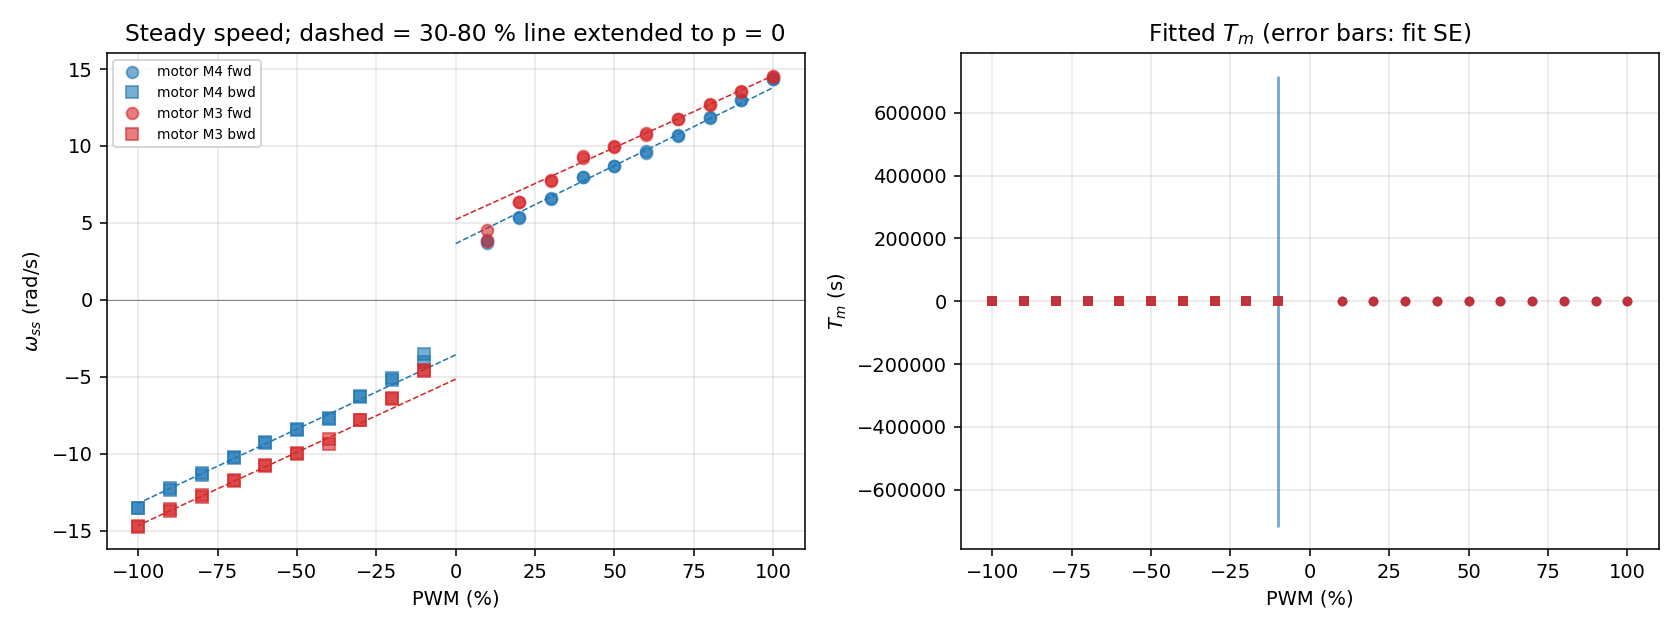

mean Tm at |PWM|=10%: 0.336  at 100%: 0.057  | mean sample interval 28.6 ms


In [73]:
def mdl(t, s, T): return s*(t-T + T*np.exp(-t/T)) # theta(t) for a step, course / intercept form

rows = []
for (motor, run, seg), h in steps[(steps.phase == 1) & (steps.pwm != 0)].groupby(['motor', 'run', 'segment']):
    t = (h.time - h.onset.iloc[0]).to_numpy(); y = (h.theta - h.theta.iloc[0]).to_numpy(); p = h.pwm.iloc[0]
    s0 = np.polyfit(t[-8:], y[-8:], 1)[0]; bnd = ([0, .001], [200, 2]) if s0 > 0 else ([-200, .001], [0, 2])
    f = lambda t, s, T: mdl(t, s, T) - mdl(t[0], s, T)
    (s, T), cov = curve_fit(f, t, y, p0=[s0, .1], bounds=bnd, maxfev=20000)
    rows.append(dict(
        motor=motor, 
        run=run, 
        pwm=p, 
        speed=s, 
        Tm=T, 
        Tm_se=np.sqrt(cov[1, 1]),
        rmse=np.sqrt(np.mean((f(t, s,T) - y)**2)), Vb=h.Vb.mean(), dt=np.diff(t).mean())
    )

fits = pd.DataFrame(rows)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5)); col = {4: 'tab:blue', 3: 'tab:red'}
for m in MOTORS:
    for sgn, mk in ((1, 'o'), (-1, 's')):
        q = fits[(fits.motor == m) & (np.sign(fits.pwm) == sgn)]
        ax[0].plot(q.pwm, q.speed, mk, color=col[m], alpha=.6, label=f'motor M{m} {"fwd" if sgn > 0 else "bwd"}')
        ax[1].errorbar(q.pwm, q.Tm, q.Tm_se, fmt=mk, color=col[m], alpha=.6, ms=4)
        q = q[q.pwm.abs().between(30, 80)]; a, b = np.polyfit(q.pwm, q.speed, 1); xx = np.array([0, 100*sgn])
        ax[0].plot(xx, a*xx + b, '--', color=col[m], lw=.8)
ax[0].axhline(0, c='gray', lw=.5)
ax[0].set(xlabel='PWM (%)', ylabel=r'$\omega_{ss}$ (rad/s)', title='Steady speed; dashed = 30-80 % line extended to p = 0'); ax[0].legend(fontsize=7)
ax[1].set(xlabel='PWM (%)', ylabel=r'$T_m$ (s)', title=r'Fitted $T_m$ (error bars: fit SE)')
for a in ax: a.grid(alpha=.3)
show(fig, 'fig1_failure')
print('mean Tm at |PWM|=10%:', fits[fits.pwm.abs() == 10].Tm.mean().round(3), ' at 100%:', fits[fits.pwm.abs() == 100].Tm.mean().round(3),
      ' | mean sample interval', round(1000*fits.dt.mean(), 1), 'ms')

*Figure 1. Left: steady speed; dashed line (30-80% range, extended) crosses the speed axis at +3.6 rad/s (motor M4) and +5.2 rad/s (motor M3) instead of the origin, so stage 1's "through the origin" line is wrong. Right: $T_m$ falls monotonically, about six-fold on average (0.34 s at 10% to 0.06 s at 100%). At high PWM the rise lasts only a few samples (sample interval about 28 ms), so $T_m$ there is the least certain.*

**Parameters of stage 1 and stage 2** (30-80% range, $U_b$ = mean battery voltage of the steps). Initial (stage 1) model uses the through-zero gain $k_e=\sum U^2/\sum U\omega$; stage 2 uses the free line $\omega=s|p|+b$. Both use the same mean $T_m$.

In [75]:
def params(m):
    f = fits[(fits.motor == m) & fits.pwm.abs().between(30, 80)]; out = {}
    for d in (1,-1):
        q = f[np.sign(f.pwm) == d]; U = q.pwm*q.Vb/100
        s, b = np.polyfit(q.pwm.abs(), q.speed.abs(), 1)
        out[d] = dict(
            Ub=q.Vb.mean(),
            ke0=(U*U).sum()/(U*q.speed).sum(), 
            s=s, b=b, 
            ke1=q.Vb.mean()/(100*s), 
            Tm=q.Tm.mean()
        )
    return out
P = {m: params(m) for m in MOTORS}
tab = pd.DataFrame([
    {'motor': f'M{m}', 
     'dir': 'fwd' if d > 0 else 'bwd', 
     'Ub (V)': v['Ub'], 
     'course: ke (V s/rad)': v['ke0'],
     '+ intercept: slope s (rad/s per %)': v['s'], 
     '+ intercept: b (rad/s)': v['b'], 
     '+ intercept: ke=Ub/(100 s)': v['ke1'], 
     'Tm (s)': v['Tm']
    } for m in MOTORS for d, v in P[m].items()]).set_index(['motor', 'dir']
)
display(tab.round(4))

Ub (V)  course: ke (V s/rad)  + intercept: slope s (rad/s per %)  \
motor dir                                                                      
M4    fwd  11.1847                0.6906                              0.1014   
      bwd  11.1887                0.7180                              0.0965   
M3    fwd  11.1847                0.6211                              0.0936   
      bwd  11.1887                0.6196                              0.0951   

           + intercept: b (rad/s)  + intercept: ke=Ub/(100 s)  Tm (s)  
motor dir                                                              
M4    fwd                  3.6528                      1.1031  0.1937  
      bwd                  3.5770                      1.1591  0.1967  
M3    fwd                  5.2173                      1.1953  0.2364  
      bwd                  5.1589                      1.1771  0.2196

## stage 3: speed-dependent loss

in step 2 model $T_m$ is considered to be constant, but fig. 1 shows displays the contrary - $T_m$ is not constant. 

let loss depend on speed:

If $\dot\omega=a(p)-\phi(\omega)$, the curves $\dot\omega$ against $\omega$ for all steps should be vertical shifts of one curve, and the coasting curve ($p=0$) should be that curve itself. $\dot\omega,\omega$ come from a smoothing spline of the measured angle.

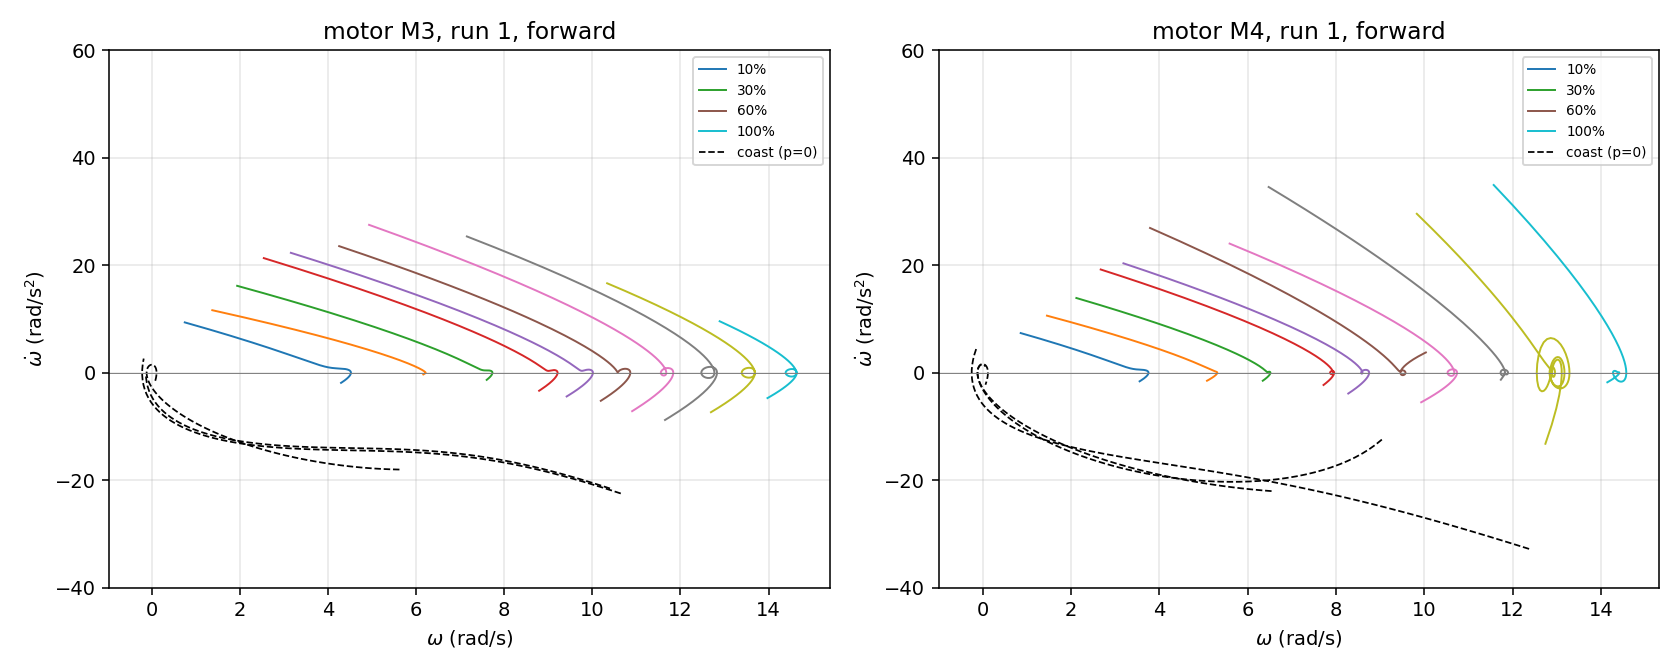

In [76]:
def spline_w(t, th, sig=0.03): return UnivariateSpline(t, th, k=5, s=len(t)*sig**2)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
for a_, m in zip(ax, (3, 4)):
    for (run, seg), h in steps[(steps.motor == m) & (steps.run == 1) & (steps.phase == 1) & (steps.pwm > 0)].groupby(['run', 'segment']):
        t = (h.time-h.onset.iloc[0]).to_numpy(); 
        sp = spline_w(t, (h.theta-h.theta.iloc[0]).to_numpy())
        tt = np.linspace(t[2], t[-1], 150);
        p = int(h.pwm.iloc[0])
        a_.plot(sp.derivative(1)(tt), sp.derivative(2)(tt), lw=1, label=f'{p}%' if p in (10, 30, 60, 100) else None)
    for p in (100, 60, 30):
        h = steps[(steps.motor == m) & (steps.run == 1) & (steps.phase == 1) & (steps.pwm == p)]; t1 = h.time.iloc[-1]
        c = steps[(steps.motor == m) & (steps.run == 1) & (steps.phase == 2) & (steps.time > t1) & (steps.time < t1 + 1)]
        t = (c.time - c.time.iloc[0]).to_numpy(); sp = spline_w(t, c.theta.to_numpy()); tt = np.linspace(0, t[-1] - .1, 80)
        a_.plot(sp.derivative(1)(tt), sp.derivative(2)(tt), 'k--', lw=.9, label='coast (p=0)' if p == 100 else None)
    a_.axhline(0, c='gray', lw=.5)
    a_.set(xlabel=r'$\omega$ (rad/s)', ylabel=r'$\dot\omega$ (rad/s$^2$)', title=f'motor M{m}, run 1, forward', ylim=(-40, 60))
    a_.legend(fontsize=7); a_.grid(alpha=.3)
show(fig, 'fig2_phase')

*figure 2. phase portraits:*
- solid: powered steps, each ending at $\dot\omega=0$ (its $\omega_{ss}$)
- dashed: coasting; powered curves are roughly vertical shifts of one another but they bend, so the effective $T_m=1/\phi'(\omega)$ shortens with speed. Coast curves have a flat plateauau of about 15 rad/s$^2$(M3) to 19 rad/s$^2$ (M4) between 3 and 12 rad/s (approx; fig. 3 gives the medians): a nearly constant deceleration, **the signature of Coulomb friction.** Motor M4 is noisier (given encoder quantisation).

**3.2 fit.** following the MuJoCo torque balance (electrical torque, viscous drag, polynomial drag $B_2\omega|\omega|$, $B_3\omega^3$, Coulomb $c\,\operatorname{sgn}\omega$) divided by $J$: $\dot\omega=a-\phi(\omega)$. 

- drive $a=Kv/(JR)$ should be linear in PWM, but the data are not => so $a$ is a free value at each tested level.
- $\phi$ is a cubic in $\omega$ (the lowest order that fitted the steps well). The Coulomb term is left out because it cannot be separated from $a$ in a steps-only fit; the coast plateau shows it exists. Linearising around $\omega_{ss}$ gives $\delta\dot\omega=-\phi'(\omega_{ss})\,\delta\omega$, hence $T_m=1/\phi'$.

There is no closed-form step response, so the equation is stepped forward ($\omega\mathrel{+}=dt\,(a-\phi(\omega))$, $\theta\mathrel{+}=dt\,\omega$) and `scipy.optimize.least_squares` adjusts the 10 values of $a$ and $k_1,k_2,k_3$ until the simulated angle matches the measured angle over all steps, the multi-parameter counterpart of `curve_fit`. 

In [78]:
def step_set(motor, dirn):
    g = steps[(steps.motor == motor) & (steps.phase == 1) & (np.sign(steps.pwm) == dirn)]; S = []
    for (run, seg), h in g.groupby(['run', 'segment']):
        t = (h.time - h.onset.iloc[0]).to_numpy(); th = dirn*(h.theta - h.theta.iloc[0]).to_numpy()
        S.append((int(round(abs(h.pwm.iloc[0]))), t, th))
    return S

def sim_levels(a_seg, k, n):
    # loss model for all steps at once, in the positive dir:  dw/dt = a - (k0*w + k1*w^2 + k2*w^3)
    w = np.zeros(len(a_seg)); th = np.zeros((n, len(a_seg)))
    for i in range(1, n):
        w = np.maximum(0, w + DT*(a_seg - k[0]*w - k[1]*w*w - k[2]*w**3)); 
        th[i] = th[i-1] + DT*w
    return th

def residuals(S, th):
    tt = np.arange(th.shape[0])*DT; r = []
    for j, s in enumerate(S):
        y = np.interp(s[1], tt, th[:, j]); 
        r.append((y - y[0]) - s[2])
    return np.concatenate(r)

def fit_loss(motor, dirn):
    S = step_set(motor, dirn); lv = sorted(set(s[0] for s in S))
    idx = np.array([lv.index(s[0]) for s in S])
    n = int(max(s[1][-1] for s in S)/DT) + 2
    f = lambda x: residuals(S, sim_levels(x[:len(lv)][idx], x[len(lv):], n))
    x0 = np.r_[np.linspace(20, 100, len(lv)), 7.9, -1.2, .08]
    r = least_squares(f, 
                      x0, 
                      bounds=(np.r_[np.zeros(len(lv)), 0, -5, -1], 
                              np.r_[np.full(len(lv), 600.), 60, 5, 1]),
                      diff_step=1e-3, 
                      x_scale=np.r_[np.full(len(lv), 10.), 1, .1, .01])
    return dict(
        levels=np.array(lv),
        a=r.x[:len(lv)], k=r.x[len(lv):],
        rmse=np.sqrt(np.mean(r.fun**2))
    )

# closed-form course / intercept model with one param set, over all steps of direction
def step_rmse(m, d, wss_of_p, Tm):     
    r = []
    for p, t, th in step_set(m, d):
        s = wss_of_p(p); r.append(mdl(t, s, Tm) - mdl(t[0], s, Tm) - th)
    return np.sqrt(np.mean(np.concatenate(r)**2))

LOSS = {}; rows2 = []
for m in MOTORS:
    for d in (1, -1):
        v = P[m][d]; LOSS[m, d] = fit_loss(m, d)
        rows2.append({'motor': f'M{m}', 'dir': 'fwd' if d > 0 else 'bwd',
            'per-step fits': fits[(fits.motor == m) & (np.sign(fits.pwm) == d)].rmse.mean(),
            'course': step_rmse(m, d, lambda p: p*v['Ub']/100/v['ke0'], v['Tm']),
            '+ intercept': step_rmse(m, d, lambda p: v['s']*p + v['b'], v['Tm']),
            '+ loss': LOSS[m, d]['rmse']})
display(Markdown('**table 1. RMS angle error over all steps (rad), one parameter set per direction (lower is better)**'))
display(pd.DataFrame(rows2).set_index(['motor', 'dir']).round(3))

**table 1. RMS angle error over all steps (rad), one parameter set per direction (lower is better)**

per-step fits  course  + intercept  + loss
motor dir                                            
M4    fwd          0.027   1.035        1.037   0.061
      bwd          0.032   1.177        0.910   0.242
M3    fwd          0.016   1.403        1.256   0.088
      bwd          0.018   1.479        1.226   0.192

*table 1. per-step fits (each step its own $T_m$) are the floor. Stage 1 and stage 2 models both use a constant $T_m$, so both are way above the floor; both are equal for M4 forward and 10-23 % lower elsewhere*.

stage 3 model removes most of the gap given $T_m$ depending on speed. The backward fits of stage 3 are worse than the forward ones (motor M4 backward is the worst, with $k_1\approx15$ against 5-8 for the other three fits.

**3.3 Coasting as an independent check of $\phi$.** Coasting is $p=0$, so $-\dot\omega=\phi_{coast}(\omega)$. It was not used in the fit.

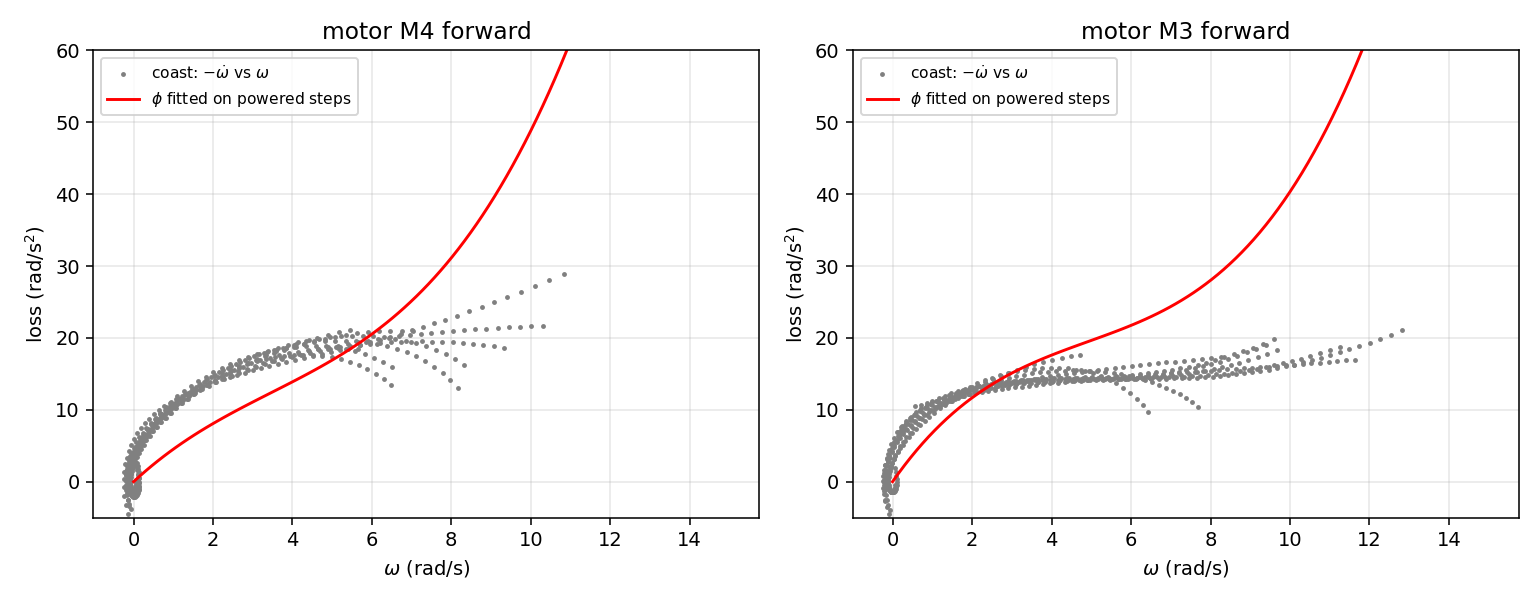

motor M4: coast deceleration for 3 < w < 12 rad/s: median 18.8 rad/s^2 (IQR 17.6-19.9)
motor M3: coast deceleration for 3 < w < 12 rad/s: median 14.8 rad/s^2 (IQR 14.3-15.9)


In [81]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.3)); stats = []
for a_, m in zip(ax, (4, 3)):
    pts = []
    for run in (1, 2):
        for p in (100, 80, 60, 40, 30):
            h = steps[(steps.motor == m) & (steps.run == run) & (steps.phase == 1) & (steps.pwm == p)]; t1 = h.time.iloc[-1]
            c = steps[(steps.motor == m) & (steps.run == run) & (steps.phase == 2) & (steps.time > t1) & (steps.time < t1 + 1)]
            t = (c.time - c.time.iloc[0]).to_numpy(); 
            
            sp = spline_w(t, c.theta.to_numpy())
            tt = np.linspace(0.05, t[-1] - .1, 60)

            pts.append(np.c_[sp.derivative(1)(tt), -sp.derivative(2)(tt)])

    pts = np.vstack(pts); k = LOSS[m, 1]['k']; u = np.linspace(0, 15, 100)
    a_.plot(pts[:, 0], pts[:, 1], '.', ms=3, color='gray', label=r'coast: $-\dot\omega$ vs $\omega$')
    a_.plot(u, k[0]*u + k[1]*u**2 + k[2]*u**3, 'r', label=r'$\phi$ fitted on powered steps')
    plat = pts[(pts[:, 0] > 3) & (pts[:, 0] < 12)]; 
    stats.append((m, np.median(plat[:, 1]), np.percentile(plat[:, 1], 25), np.percentile(plat[:, 1], 75)))
    a_.set(xlabel=r'$\omega$ (rad/s)', ylabel=r'loss (rad/s$^2$)', title=f'motor M{m} forward', ylim=(-5, 60)); 
    a_.legend(fontsize=8); 
    a_.grid(alpha=.3)
show(fig, 'fig3_coast')
for m, med, lo, hi in stats: print(f'motor M{m}: coast deceleration for 3 < w < 12 rad/s: median {med:.1f} rad/s^2 (IQR {lo:.1f}-{hi:.1f})')

*figure 3. coast deceleration (grey) against the loss identified from powered steps (red).*

In range below about 3 rad/s they agree, but above that the coast loss flattens (about 15 rad/s^2 for motor M3, about 20 for motor M4) while the powered $\phi$ keeps rising to 40-50 rad/s$^2$ at 10 rad/s. 

2 possible causes that the data cannot separate: 
- back-EMF braking exists only while the driver is powered, so it is absent at power 0 if TRIK leaves the terminals open;
- the cubic $\phi$ partly compensates a nonlinear PWM-to-voltage map, since $a(p)$ and $\phi$ can trade off in a steps-only fit

## 4. Validation on the signals (held out)

All 3 models are identified **from the steps only**; every signal recording is then simulated from its recorded PWM, with the equation stepped forward in $dt=2$ms increments. Scoring as in the main report: samples with phase != 0, speed from `np.gradient` of the angle with a 5-sample moving average, fit $=100(1-\|y-\hat y\|/\|y-\bar y\|)$.

there are 2 recorded sets:
- set A: (battery 11.19 V): square and sawtooth
- set B: (battery 10.89 V): square (`square_B`), sawtooth (`sawtooth_B`) and **triangle** with period 4s

in the tables and figures the labels are: **course** = stage 1, **+ intercept** = stage 2, **+ loss** = stage 3

In [84]:
NAMES = {1: 'square', 2: 'sawtooth', 11: 'square_B', 12: 'sawtooth_B', 13: 'triangle'}   # run -> signal (B = second session)
RUNS = sorted(signal.run.unique())

def hold(g):
    ch = g.pwm.ne(g.pwm.shift()).to_numpy(); return g.onset.to_numpy()[ch], g.pwm.to_numpy()[ch]

def sim_first_order(g, wss_of, Tm_of): # course and intercept models:  Tm dw/dt = wss(p) - w
    t = g.time.to_numpy(); on, cmd = hold(g)
    tg = np.arange(t[0], t[-1] + DT, DT)
    w = 0.; th = 0.; 
    W = np.zeros(len(tg)); 
    TH = np.zeros(len(tg))
    for i, tt in enumerate(tg):
        p = cmd[max(np.searchsorted(on, tt, side='right') - 1, 0)]
        w += DT*(wss_of(p) - w)/Tm_of(p)
        th += DT*w;
        W[i] = w; 
        TH[i] = th;
    return np.interp(t,tg,W), np.interp(t,tg,TH)

def sim_loss(g, Mf, Mb): # dw/dt = sgn(p) a(|p|) - sgn(w) phi(|w|)
    t = g.time.to_numpy(); 
    on, cmd = hold(g); 
    tg = np.arange(t[0], t[-1]+DT, DT); 
    w = 0.; th = 0.; 
    W = np.zeros(len(tg)); TH = np.zeros(len(tg))

    for i, tt in enumerate(tg):
        p = cmd[max(np.searchsorted(on, tt, side='right')-1, 0)]; 
        M = Mf if p>0 else Mb
        drive = np.sign(p)*np.interp(abs(p), np.r_[0, M['levels']], np.r_[0, M['a']]) if p != 0 else 0.
        d = np.sign(w) if abs(w) > 1e-6 else np.sign(drive); k = (Mf if d >= 0 else Mb)['k']; u = abs(w)
        wn = w + DT*(drive-d*(k[0]*u + k[1]*u*u + k[2]*u**3))
        if w*wn < 0 and (drive == 0 or np.sign(drive) == np.sign(w)): wn = 0.  # friction cant reverse the wheel
        w = wn; th += DT*w; 
        W[i] = w; 
        TH[i] = th
    return np.interp(t, tg, W), np.interp(t, tg, TH)

def metrics(y, yh): return np.sqrt(np.mean((y - yh)**2)), 100*(1 - np.linalg.norm(y - yh)/np.linalg.norm(y - y.mean()))
def sig(m, run): return signal[(signal.motor == m) & (signal.run == run)]

def row(m, name, lab, g, w, th): # scores of one simulated run
    t = g.time.to_numpy(); y = (g.theta - g.theta.iloc[0]).to_numpy(); mk = g.phase.to_numpy() != 0
    wm = uniform_filter1d(np.gradient(y, t), 5, mode='nearest')
    ra = metrics(y[mk], (th - th[0])[mk]); rw = metrics(wm[mk], uniform_filter1d(w, 5, mode='nearest')[mk])
    return dict(motor=f'M{m}', signal=name, model=lab, angle_rmse=ra[0], angle_fit=ra[1], speed_rmse=rw[0], speed_fit=rw[1])

rows = []; sims = {}
for m in MOTORS:
    v = P[m]; q = lambda d: v[1 if d >= 0 else -1]
    models = {'course': lambda g: sim_first_order(g, lambda p: p*g.Vb.mean()/100/q(p)['ke0'], lambda p: q(p)['Tm']),
              '+ intercept': lambda g: sim_first_order(g, lambda p: np.sign(p)*(q(p)['s']*abs(p) + q(p)['b'])*min(1, abs(p)/10) if p else 0., lambda p: q(p)['Tm']),
              '+ loss': lambda g: sim_loss(g, LOSS[m, 1], LOSS[m, -1])}
    for run in RUNS:
        name = NAMES.get(run, f'run {run}'); g = sig(m, run)
        for lab, simf in models.items():
            w, th = simf(g); sims[m, name, lab] = (w, th - th[0]); rows.append(row(m, name, lab, g, w, th))
res = pd.DataFrame(rows)
display(Markdown('**table 2. held-out validation (fit in %, RMSE in rad or rad/s)**')); 
display(res.round(2).set_index(['motor', 'signal', 'model']))

**table 2. held-out validation (fit in %, RMSE in rad or rad/s)**

angle_rmse  angle_fit  speed_rmse  speed_fit
motor signal     model                                                    
M4    square     course             0.18      86.92        0.64      87.59
                 + intercept        0.18      87.17        0.64      87.68
                 + loss             0.24      83.31        0.70      86.50
      sawtooth   course             2.27     -75.11        1.08      68.72
                 + intercept        2.25     -73.70        0.68      80.38
                 + loss             2.32     -79.07        0.83      76.07
      square_B   course             0.65      50.16        0.71      86.25
                 + intercept        0.71      45.52        0.63      87.82
                 + loss             0.75      42.78        0.81      84.31
      sawtooth_B course             2.01    -118.70        0.84      73.39
                 + intercept        1.90    -107.11        0.47      84.91
                 + loss             1.98    -115.46        0.53      83.13
      triangle   course             0.71      80.42        1.29      76.82
                 + intercept        0.52      85.63        0.70      87.48
                 + loss             0.46      87.40        0.72      87.01
M3    square     course             0.65      64.94        0.88      84.22
                 + intercept        0.66      64.58        0.87      84.34
                 + loss             0.73      60.72        1.11      79.94
      sawtooth   course             3.91     -44.42        1.36      62.37
                 + intercept        3.48     -28.53        0.92      74.52
                 + loss             3.80     -40.39        1.14      68.46
      square_B   course             0.71      54.79        0.78      85.39
                 + intercept        0.72      54.55        0.71      86.72
                 + loss             0.56      64.68        1.08      79.67
      sawtooth_B course             2.22     -70.62        0.86      73.65
                 + intercept        1.66     -27.27        0.59      82.00
                 + loss             2.14     -64.03        0.58      82.13
      triangle   course             0.89      78.25        1.52      75.73
                 + intercept        0.54      86.81        0.92      85.27
                 + loss             0.43      89.49        0.49      92.22

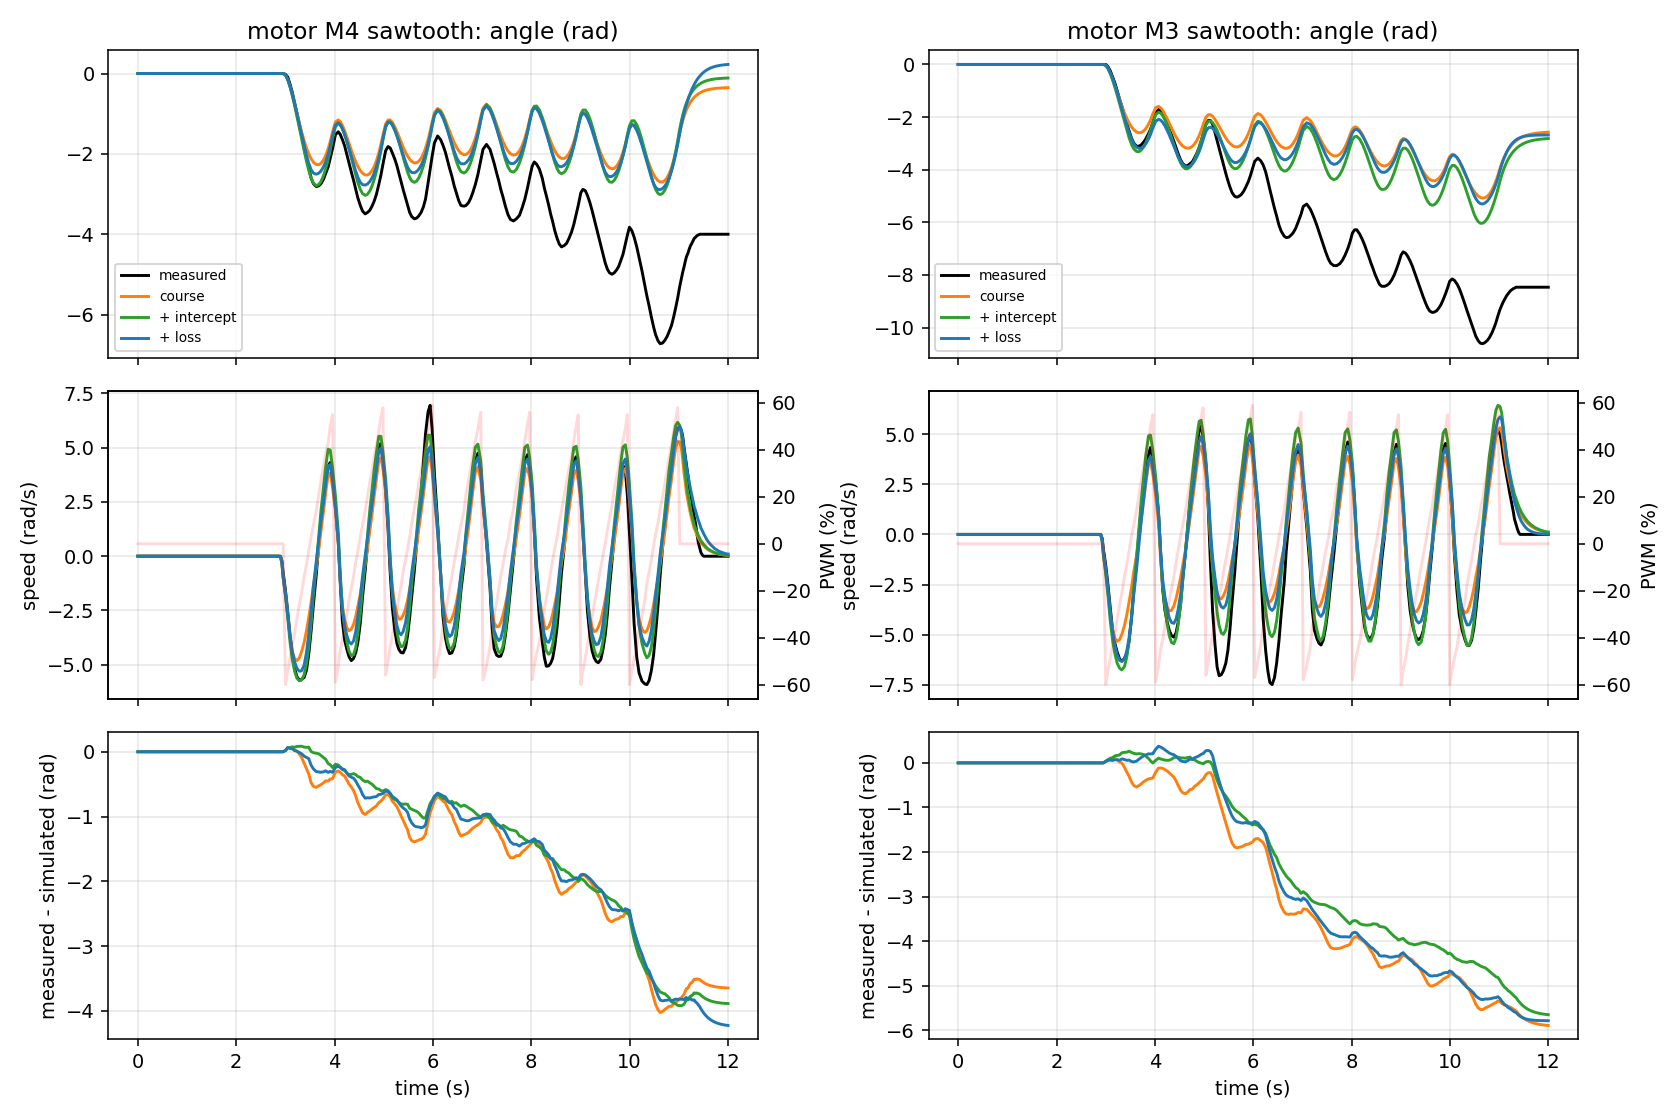

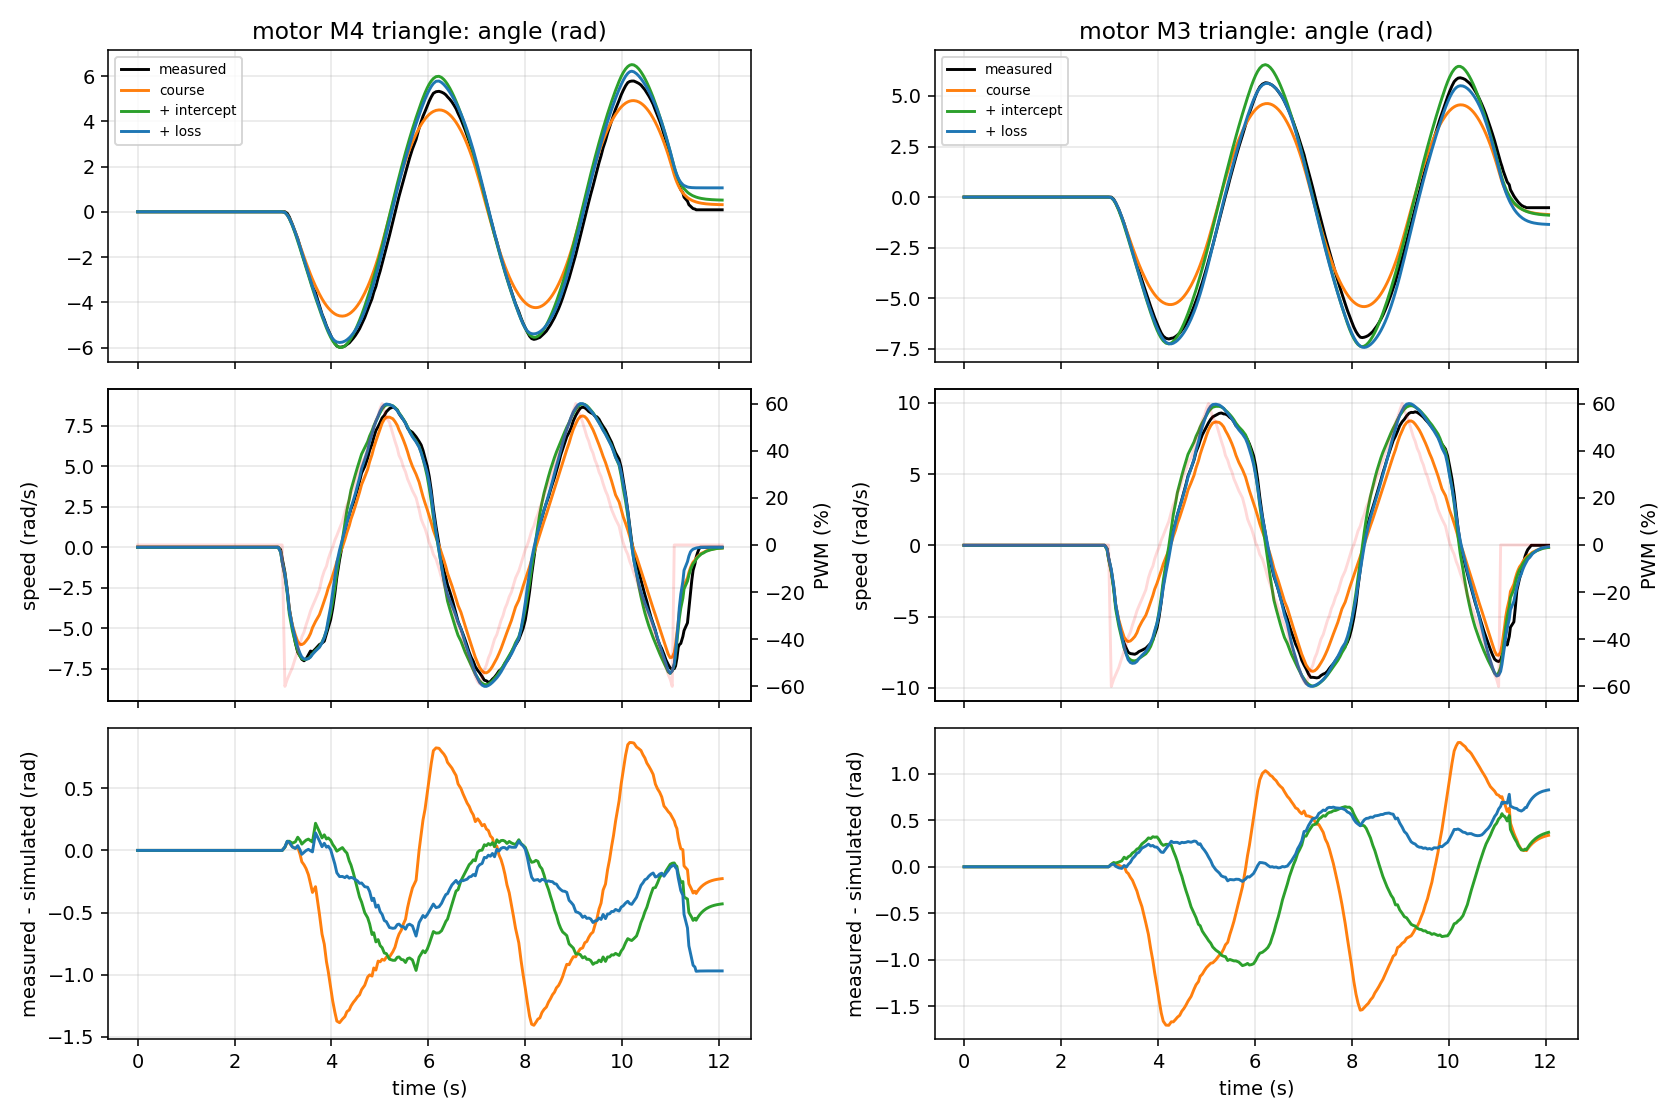

In [85]:
for run in (2, 13): # sawtooth (hardest case) and triangle (best case); the other runs are in table 2
    name = NAMES[run]
    fig, axes = plt.subplots(3, 2, figsize=(12, 8), sharex='col')
    for c, m in enumerate(MOTORS):
        g = sig(m, run); t = g.time.to_numpy() - g.time.iloc[0]; y = (g.theta - g.theta.iloc[0]).to_numpy()
        wm = uniform_filter1d(np.gradient(y, t), 5, mode='nearest')
        axes[0, c].plot(t, y, 'k', label='measured'); axes[1, c].plot(t, wm, 'k', label='measured (5-pt mean)')
        for lab, colr in (('course', 'tab:orange'), ('+ intercept', 'tab:green'), ('+ loss', 'tab:blue')):
            w, th = sims[m, name, lab]
            axes[0, c].plot(t, th, color=colr, label=lab); axes[1, c].plot(t, uniform_filter1d(w, 5), color=colr, label=lab)
            axes[2, c].plot(t, y - th, color=colr, label=lab)
        ax2 = axes[1, c].twinx(); ax2.plot(t, g.pwm, color='r', alpha=.15); ax2.set_ylabel('PWM (%)')
        axes[0, c].set(title=f'motor M{m} {name}: angle (rad)'); axes[1, c].set(ylabel='speed (rad/s)')
        axes[2, c].set(ylabel='measured - simulated (rad)', xlabel='time (s)')
        for a in axes[:, c]: a.grid(alpha=.3)
        axes[0, c].legend(fontsize=7)
    show(fig, f'fig4_{name}')

fig. 4 (sawtooth, triangle: angle, speed with PWM faint on the right axis, angle error)

- sawtooth: stage 2 model beats stage 1 on speed fit in both sets (set A: motor M4 69 -> 80%, motor M3 62 -> 75%; set B: M4 73 -> 85%, M3 74 -> 82%), so the gain repeats. Stage 3 model also improves on stage 1 (speed fit +6 to +10 points) and is similar to stage 2 in set B.
- square: stage 2 is equal to stage 1 in set A (within 0.4 points) and 1-2 points better on speed in set B (angle fit equal or a few points lower). Stage 3 model is worse than stage 1 on 7 of the 8 square rows.
- triangle (new, never used in any fit):
    - angle fit for all 3 models (M4/M3 PWM%): 1 - 80%/78%, 2 - 86%/87%, 3 - 87%/89%;
    - speed fit for all 3 models (M4/M3 PWM%): 1- 77%/76%, 2 - 87%/85%, 3 - 87%/92%;
    - stage model 3 is clearly best for motor M3 and about equal to stage 2 model for motor M4.
- angle drift: the sawtooth angle fit is negative for all 3 models in both sets (-27% to -119%). Measured wheel drifts to negative angle while the simulations stay much closer to zero, although the input is nearly zero-mean. In the speed graphs, the deepest negative lobes right after the jump from about +58% to -60% are underestimated: real wheel brakes and reverses direction much faster and harder than simulation predicted.
- set B square angle fit is lower than session A for both motors (M4: 87% -> 43-50%, M3: 65% -> 55%, except stage 3 model on M3 at 65%). stage 1 scales with the actual battery voltage and is also lower, so the 0.3V lower battery alone does not explain it. (im honestly not sure what couldve caused this)

so stage 3 model explains the changing $T_m$ and gives the best triangle fit for motor M3, but it is not consistently better than the far simpler stage 2 model on the signals (with Tm=const): its extra parameters are fitted to the steps and do not transfer uniformly.

## 5. final formulas with coefficients plugged in 

In [86]:
def sg(x, nd=3): return f'{x:+.{nd}f}'
lines = ['**stage 2 model** (use for prediction; $p$ in %, $|p|\\ge10$, speeds in rad/s; below 10 % ramp linearly to 0):\n']
for m in MOTORS:
    for d, nm in ((1, 'forward'), (-1, 'backward')):
        v = P[m][d]
        lines.append(f'- motor M{m} {nm}: $\\omega_{{ss}}(p)={"+" if d>0 else "-"}\\,({v["s"]:.4f}\\,|p|{sg(v["b"],2)})$, $T_m={v["Tm"]:.3f}$ s, $k_e=U_b/(100s)={v["ke1"]:.3f}$ V s/rad')
lines.append('\n**stage 3 model** ($\\phi(u)=k_1u+k_2u^2+k_3u^3$; $a$ in rad/s$^2$ at $p=10,20,\\dots,100\\,\\%$):\n')
for m in MOTORS:
    for d, nm in ((1, 'forward'), (-1, 'backward')):
        M = LOSS[m, d]; k = M['k']
        lines.append(f'- motor M{m} {nm}: $\\phi(u)={k[0]:.2f}u{sg(k[1],2)}u^2{sg(k[2],3)}u^3$;  $a$ = ' + ', '.join(f'{x:.0f}' for x in M['a']) + f'  (step RMSE {M["rmse"]:.2f} rad)')
display(Markdown('\n'.join(lines)))

**stage 2 model** (use for prediction; $p$ in %, $|p|\ge10$, speeds in rad/s; below 10 % ramp linearly to 0):

- motor M4 forward: $\omega_{ss}(p)=+\,(0.1014\,|p|+3.65)$, $T_m=0.194$ s, $k_e=U_b/(100s)=1.103$ V s/rad
- motor M4 backward: $\omega_{ss}(p)=-\,(0.0965\,|p|+3.58)$, $T_m=0.197$ s, $k_e=U_b/(100s)=1.159$ V s/rad
- motor M3 forward: $\omega_{ss}(p)=+\,(0.0936\,|p|+5.22)$, $T_m=0.236$ s, $k_e=U_b/(100s)=1.195$ V s/rad
- motor M3 backward: $\omega_{ss}(p)=-\,(0.0951\,|p|+5.16)$, $T_m=0.220$ s, $k_e=U_b/(100s)=1.177$ V s/rad

**stage 3 model** ($\phi(u)=k_1u+k_2u^2+k_3u^3$; $a$ in rad/s$^2$ at $p=10,20,\dots,100\,\%$):

- motor M4 forward: $\phi(u)=5.13u-0.67u^2+0.065u^3$;  $a$ = 13, 18, 23, 31, 36, 43, 56, 72, 95, 130  (step RMSE 0.06 rad)
- motor M4 backward: $\phi(u)=14.94u-2.36u^2+0.151u^3$;  $a$ = 31, 35, 38, 45, 49, 56, 67, 85, 109, 149  (step RMSE 0.24 rad)
- motor M3 forward: $\phi(u)=7.92u-1.21u^2+0.082u^3$;  $a$ = 18, 23, 27, 34, 39, 46, 55, 71, 90, 116  (step RMSE 0.09 rad)
- motor M3 backward: $\phi(u)=6.05u-0.88u^2+0.067u^3$;  $a$ = 15, 21, 25, 35, 38, 44, 56, 73, 91, 118  (step RMSE 0.19 rad)